In [2]:
import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [3]:
import pandas as pd
import os

path = kagglehub.competition_download('cats-and-dogs-plus-plus')

print("Path to competition files:", path)

train_df = pd.read_csv(os.path.join(path, "train.csv"))
test_df = pd.read_csv(os.path.join(path, "test.csv"))

100%|██████████| 1.66G/1.66G [00:29<00:00, 60.4MB/s]

Extracting files...


Path to competition files: /root/.cache/kagglehub/competitions/cats-and-dogs-plus-plus


In [4]:
!pip install wandb

In [5]:
!pip install -q timm lightning torchmetrics

import timm, lightning, torchmetrics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 23.3 MB/s eta 0:00:00


In [6]:
import wandb
from google.colab import userdata
wandb.login(key=userdata.get("WANDB_API_KEY"))

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [7]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
import os
CKPT_DIR = "/content/drive/MyDrive/cats_dogs_pp/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

In [9]:
!pip install -q iterative-stratification

In [10]:
import os
import pandas as pd
import kagglehub
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

kagglehub.login()
path = kagglehub.competition_download("cats-and-dogs-plus-plus")

LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]
train_df = pd.read_csv(os.path.join(path, "train.csv"))
test_df = pd.read_csv(os.path.join(path, "test.csv"))

FOLDS_PATH = "/content/drive/MyDrive/cats_dogs_pp/folds.csv"

if os.path.exists(FOLDS_PATH):
    folds = pd.read_csv(FOLDS_PATH)
    train_df = train_df.merge(folds, on="image_id")
    print("фолди завантажено з Drive")

else:
    train_df["fold"] = -1
    mskf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for f, (_, val_idx) in enumerate(mskf.split(train_df, train_df[LABELS])):
        train_df.loc[val_idx, "fold"] = f

    os.makedirs(os.path.dirname(FOLDS_PATH), exist_ok=True)
    train_df[["image_id", "fold"]].to_csv(FOLDS_PATH, index=False)
    print("фолди створено і збережено на Drive")

print(train_df.groupby("fold")[LABELS].sum())

фолди завантажено з Drive
       Cat   Dog  Moris  Motya  Biatrix
fold                                   
0     1015  1005     11      8        9
1     1016  1005     12      8        8
2     1015  1005     11      9        8
3     1016  1005     11      8        8
4     1015  1005     11      9        8


In [11]:
import os
import torch
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms as T

IMG_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

val_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])


class PetsDataset(Dataset):
    def __init__(self, df, folder, transform, with_labels=True):
        self.ids = df["image_id"].values
        self.labels = df[LABELS].values.astype("float32") if with_labels else None
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_path = os.path.join(path, self.folder, f"{self.ids[idx]}.jpg")
        img = Image.open(img_path).convert("RGB")
        img = self.transform(img)
        if self.labels is None:
            return img

        return img, torch.tensor(self.labels[idx])

In [12]:
ds = PetsDataset(train_df, "train", val_tf)
img, y = ds[0]
print(len(ds), img.shape, y)

test_ds = PetsDataset(test_df, "test", val_tf, with_labels=False)
print(len(test_ds), test_ds[0].shape)

12260 torch.Size([3, 224, 224]) tensor([0., 0., 0., 0., 0.])
18390 torch.Size([3, 224, 224])


In [13]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

def make_loaders(fold, batch_size=BATCH_SIZE):
    tr = train_df[train_df["fold"] != fold]
    va = train_df[train_df["fold"] == fold]

    train_loader = DataLoader(PetsDataset(tr, "train", train_tf), batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)

    val_loader = DataLoader(PetsDataset(va, "train", val_tf), batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

    return train_loader, val_loader




In [14]:
train_loader, val_loader = make_loaders(fold=0)

print("train:", len(train_loader.dataset), "фото,", len(train_loader), "батчів")
print("val:  ", len(val_loader.dataset), "фото,", len(val_loader), "батчів")

x, y = next(iter(train_loader))
print(x.shape, y.shape)

train: 9808 фото, 307 батчів
val:   2452 фото, 77 батчів
torch.Size([32, 3, 224, 224]) torch.Size([32, 5])


We use EfficientNet-B0 from timm (pretrained on ImageNet-1k). It is small (4M parameters)
and fast enough for Colab, strong for its size, and it is the organizers' baseline model.

In [15]:
import timm
print(timm.list_pretrained("efficientnet_b0*"))

['efficientnet_b0.ra4_e3600_r224_in1k', 'efficientnet_b0.ra_in1k']


In [16]:


MODEL_NAME = "efficientnet_b0.ra_in1k"


tmp = timm.create_model(MODEL_NAME, pretrained=True, num_classes=5)
cfg = timm.data.resolve_data_config({}, model=tmp)
print("mean:", cfg["mean"], "| std:", cfg["std"], "| input:", cfg["input_size"])
print("параметрів:", sum(p.numel() for p in tmp.parameters()) / 1e6, "M")
del tmp

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

mean: (0.485, 0.456, 0.406) | std: (0.229, 0.224, 0.225) | input: (3, 224, 224)
параметрів: 4.013953 M


In [17]:
import torch
import torch.nn as nn
import lightning as L
from torchmetrics.classification import MultilabelF1Score


class PetsModel(L.LightningModule):
    def __init__(self, model_name=MODEL_NAME, lr=1e-3, optimizer="adam",
                 scheduler=None):
        super().__init__()
        self.save_hyperparameters()
        self.model = timm.create_model(model_name, pretrained=True, num_classes=len(LABELS))
        self.criterion = nn.BCEWithLogitsLoss()
        self.val_f1 = MultilabelF1Score(num_labels=len(LABELS), average="macro")

    def forward(self, x):
        return self.model(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.criterion(self(x), y)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        self.val_f1.update(torch.sigmoid(logits), y.int())
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)

    def on_validation_epoch_end(self):
        self.log("val_f1", self.val_f1.compute(), prog_bar=True)
        self.val_f1.reset()

    def configure_optimizers(self):
      opt_cls = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}[self.hparams.optimizer]
      optimizer = opt_cls(self.parameters(), lr=self.hparams.lr)

      if self.hparams.scheduler == "plateau":
          sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)

          return {"optimizer": optimizer, "lr_scheduler": {"scheduler": sched, "monitor": "val_f1", "interval": "epoch"}}

      return optimizer

In [18]:
import wandb
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor

FOLD, EPOCHS = 0, 5
RUN_NAME = "run1_baseline_effb0_adam"

train_loader, val_loader = make_loaders(FOLD)

model = PetsModel(lr=1e-3, optimizer="adam", scheduler=None)

wandb_logger = WandbLogger(project="cats-dogs-pp", name=RUN_NAME)
checkpoint_cb = ModelCheckpoint(dirpath=CKPT_DIR, filename=RUN_NAME + "-{epoch:02d}-{val_f1:.4f}",  monitor="val_f1", mode="max", save_top_k=1)

trainer = L.Trainer(max_epochs=EPOCHS, accelerator="gpu", precision="16-mixed", logger=wandb_logger, callbacks=[checkpoint_cb, LearningRateMonitor("step")])

trainer.fit(model, train_loader, val_loader)
wandb.finish()

print("найкраща модель:", checkpoint_cb.best_model_path)
print("найкращий val_f1:", float(checkpoint_cb.best_model_score))

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/drive/MyDrive/cats_dogs_pp/checkpoints exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ EfficientNet      │  4.0 M │ train │     0 │
│ 1 │ criterion │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 2 │ val_f1    │ MultilabelF1Score │      0 │ train │     0 │
└───┴───────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 4.0 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.0 M                                                                                                
Total estimated model params size (MB): 16.056                                                                     
Modules in train mode: 339                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: 
Detected KeyboardInterrupt, attempting graceful shutdown ...
INFO:lightning.pytorch.utilities.rank_zero:
Detected KeyboardInterrupt, attempting graceful shutdown ...


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/call.py", line 49, in _call_and_handle_interrupt
    return trainer_fn(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 630, in _fit_impl
    self._run(model, ckpt_path=ckpt_path, weights_only=weights_only)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 1079, in _run
    results = self._run_stage()
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/trainer.py", line 1123, in _run_stage
    self.fit_loop.run()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py", line 217, in run
    self.advance()
    ~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py", line 469, in advance
    self.

TypeError: object of type 'NoneType' has no len()

In [19]:
def make_submission(ckpt_path, run_name, threshold=0.5):
    model = PetsModel.load_from_checkpoint(ckpt_path).eval().cuda()
    test_loader = DataLoader(PetsDataset(test_df, "test", val_tf, with_labels=False), batch_size=64, shuffle=False, num_workers=2)
    probs = []
    with torch.no_grad():
        for x in test_loader:
            probs.append(torch.sigmoid(model(x.cuda())).cpu())
    probs = torch.cat(probs).numpy()

    sub = pd.DataFrame((probs > threshold).astype(int), columns=LABELS)
    sub.insert(0, "image_id", test_df["image_id"].values)
    out = f"/content/drive/MyDrive/cats_dogs_pp/submissions/{run_name}.csv"
    os.makedirs(os.path.dirname(out), exist_ok=True)
    sub.to_csv(out, index=False)
    print("збережено:", out)
    return sub

make_submission(checkpoint_cb.best_model_path, "run1_baseline_effb0_adam")

KeyboardInterrupt: 

In [29]:
def run_experiment(run_name, fold=0, epochs=5, **model_kwargs):
    wandb.finish()
    train_loader, val_loader = make_loaders(fold)
    model = PetsModel(**model_kwargs)

    wandb_logger = WandbLogger(project="cats-dogs-pp", name=run_name)
    checkpoint_cb = ModelCheckpoint(dirpath=CKPT_DIR, filename=run_name + "-{epoch:02d}-{val_f1:.4f}", monitor="val_f1", mode="max", save_top_k=1)

    trainer = L.Trainer(max_epochs=epochs, accelerator="gpu", precision="16-mixed", logger=wandb_logger, callbacks=[checkpoint_cb, LearningRateMonitor("epoch")])
    trainer.fit(model, train_loader, val_loader)
    wandb.finish()

    print(f"{run_name}: best val_f1 = {float(checkpoint_cb.best_model_score):.4f}")
    make_submission(checkpoint_cb.best_model_path, run_name)

    return checkpoint_cb.best_model_path

In [ ]:

run_experiment("run2_adamw", lr=1e-3, optimizer="adamw", scheduler=None)


run_experiment("run3_plateau", lr=1e-3, optimizer="adamw", scheduler="plateau")


run_experiment("run4_lr3e-4", lr=3e-4, optimizer="adamw", scheduler="plateau")

Own block. The idea create our own head for EfficientNet instead linear layer. It should increase score


In [20]:
backbone = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0)

In [27]:
class PetsModel(L.LightningModule):
    def __init__(self, model_name=MODEL_NAME, lr=1e-3, optimizer="adam",
                 scheduler=None, head="linear"):
        super().__init__()
        self.save_hyperparameters()

        if head == "linear":

            self.backbone = timm.create_model(model_name, pretrained=True, num_classes=len(LABELS))
            self.head = nn.Identity()

        elif head == "mlp":
            self.backbone = timm.create_model(model_name, pretrained=True, num_classes=0)
            n_feat = self.backbone.num_features
            self.head = nn.Sequential(
                nn.Linear(n_feat, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.3),
                nn.Linear(512, len(LABELS)),
            )

        self.criterion = nn.BCEWithLogitsLoss()
        self.val_f1 = MultilabelF1Score(num_labels=len(LABELS), average="macro")

    def forward(self, x):
        return self.head(self.backbone(x))

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.criterion(self(x), y)
        self.log("train_loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        loss = self.criterion(logits, y)
        self.val_f1.update(torch.sigmoid(logits), y.int())
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)

    def on_validation_epoch_end(self):
        self.log("val_f1", self.val_f1.compute(), prog_bar=True)
        self.val_f1.reset()

    def configure_optimizers(self):
      opt_cls = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}[self.hparams.optimizer]
      optimizer = opt_cls(self.parameters(), lr=self.hparams.lr)

      if self.hparams.scheduler == "plateau":
          sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)

          return {"optimizer": optimizer, "lr_scheduler": {"scheduler": sched, "monitor": "val_f1", "interval": "epoch"}}

      return optimizer

In [28]:
run_experiment("run5_mlp_head", lr=3e-4, optimizer="adamw", scheduler="plateau", head="mlp")

INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loggers/wandb.py:400: There is a wandb

┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone  │ EfficientNet      │  4.0 M │ train │     0 │
│ 1 │ head      │ Sequential        │  659 K │ train │     0 │
│ 2 │ criterion │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 3 │ val_f1    │ MultilabelF1Score │      0 │ train │     0 │
└───┴───────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 4.7 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.7 M                                                                                                
Total estimated model params size (MB): 18.668                                                                     
Modules in train mode: 345                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


epoch,▁▁▁▁▁▁▁▃▃▃▃▃▁▁▁▁▁▃▃▃▃▃▅▅▅▅▅▅▆▆▆▆▆▆██████
lr-Adam,▁▁▁▁▁▁▁▁▁▁▁▁
lr-AdamW,▁▁▁▁▁
train_loss_epoch,██▂▁▁▁
train_loss_step,▆█▂▃▇▅▃▃▆▄█▂▅▅▃▄▃▄▂▂▂▅▄▂▃▁▁▃▁▁▁▁▁▃▁▂▂▁▁▁
trainer/global_step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▁▂▂▂▂▃▃▄▄▄▄▄▄▅▅▆▆▆▇▇▇▇▇██
val_f1,▃▁▆██▇
val_loss,█▃▂▁▂▃
epoch,4
lr-Adam,0.001
lr-AdamW,0.0003


run5_mlp_head: best val_f1 = 0.8929
збережено: /content/drive/MyDrive/cats_dogs_pp/submissions/run5_mlp_head.csv


'/content/drive/MyDrive/cats_dogs_pp/checkpoints/run5_mlp_head-epoch=03-val_f1=0.8929.ckpt'

In [30]:
run_experiment("run5_mlp_head", lr=3e-4, optimizer="adamw", scheduler="plateau", head="mlp")


INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
wandb: Currently logged in as: akorniienko (akorniienko-kse) to https://api.wandb.ai. Use `wandb

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/drive/MyDrive/cats_dogs_pp/checkpoints exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ backbone  │ EfficientNet      │  4.0 M │ train │     0 │
│ 1 │ head      │ Sequential        │  659 K │ train │     0 │
│ 2 │ criterion │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 3 │ val_f1    │ MultilabelF1Score │      0 │ train │     0 │
└───┴───────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 4.7 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.7 M                                                                                                
Total estimated model params size (MB): 18.668                                                                     
Modules in train mode: 345                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


epoch,▁▁▁▁▁▁▁▁▃▃▃▃▃▃▃▃▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆████████
lr-AdamW,▁▁▁▁▁
train_loss_epoch,█▂▁▁▁
train_loss_step,█▅▅▃▃▄▃▂▁▂▁▁▁▂▂▁▁▂▁▁▂▁▁▁▁▂▁▁▁▃
trainer/global_step,▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇███
val_f1,▁▆███
val_loss,█▁▄▂▂
epoch,4
lr-AdamW,0.0003
train_loss_epoch,0.00999
train_loss_step,0.02799


run5_mlp_head: best val_f1 = 0.9450
збережено: /content/drive/MyDrive/cats_dogs_pp/submissions/run5_mlp_head.csv


'/content/drive/MyDrive/cats_dogs_pp/checkpoints/run5_mlp_head-epoch=03-val_f1=0.9450.ckpt'

Own block: MLP head vs linear head

We replaced the default linear head of EfficientNet-B0 with a custom MLP head
(Linear → BatchNorm → ReLU → Dropout) and compared it with the best previous run (run4),
keeping all other settings the same.

- run4 (linear head): val_F1 = 0.91 (approximately)
- run5 (MLP head):    val_F1 = 0.9450

The MLP head gave a higher val_F1 and lower validation loss but slightly higher training loss
so Dropout likely reduced overfitting.

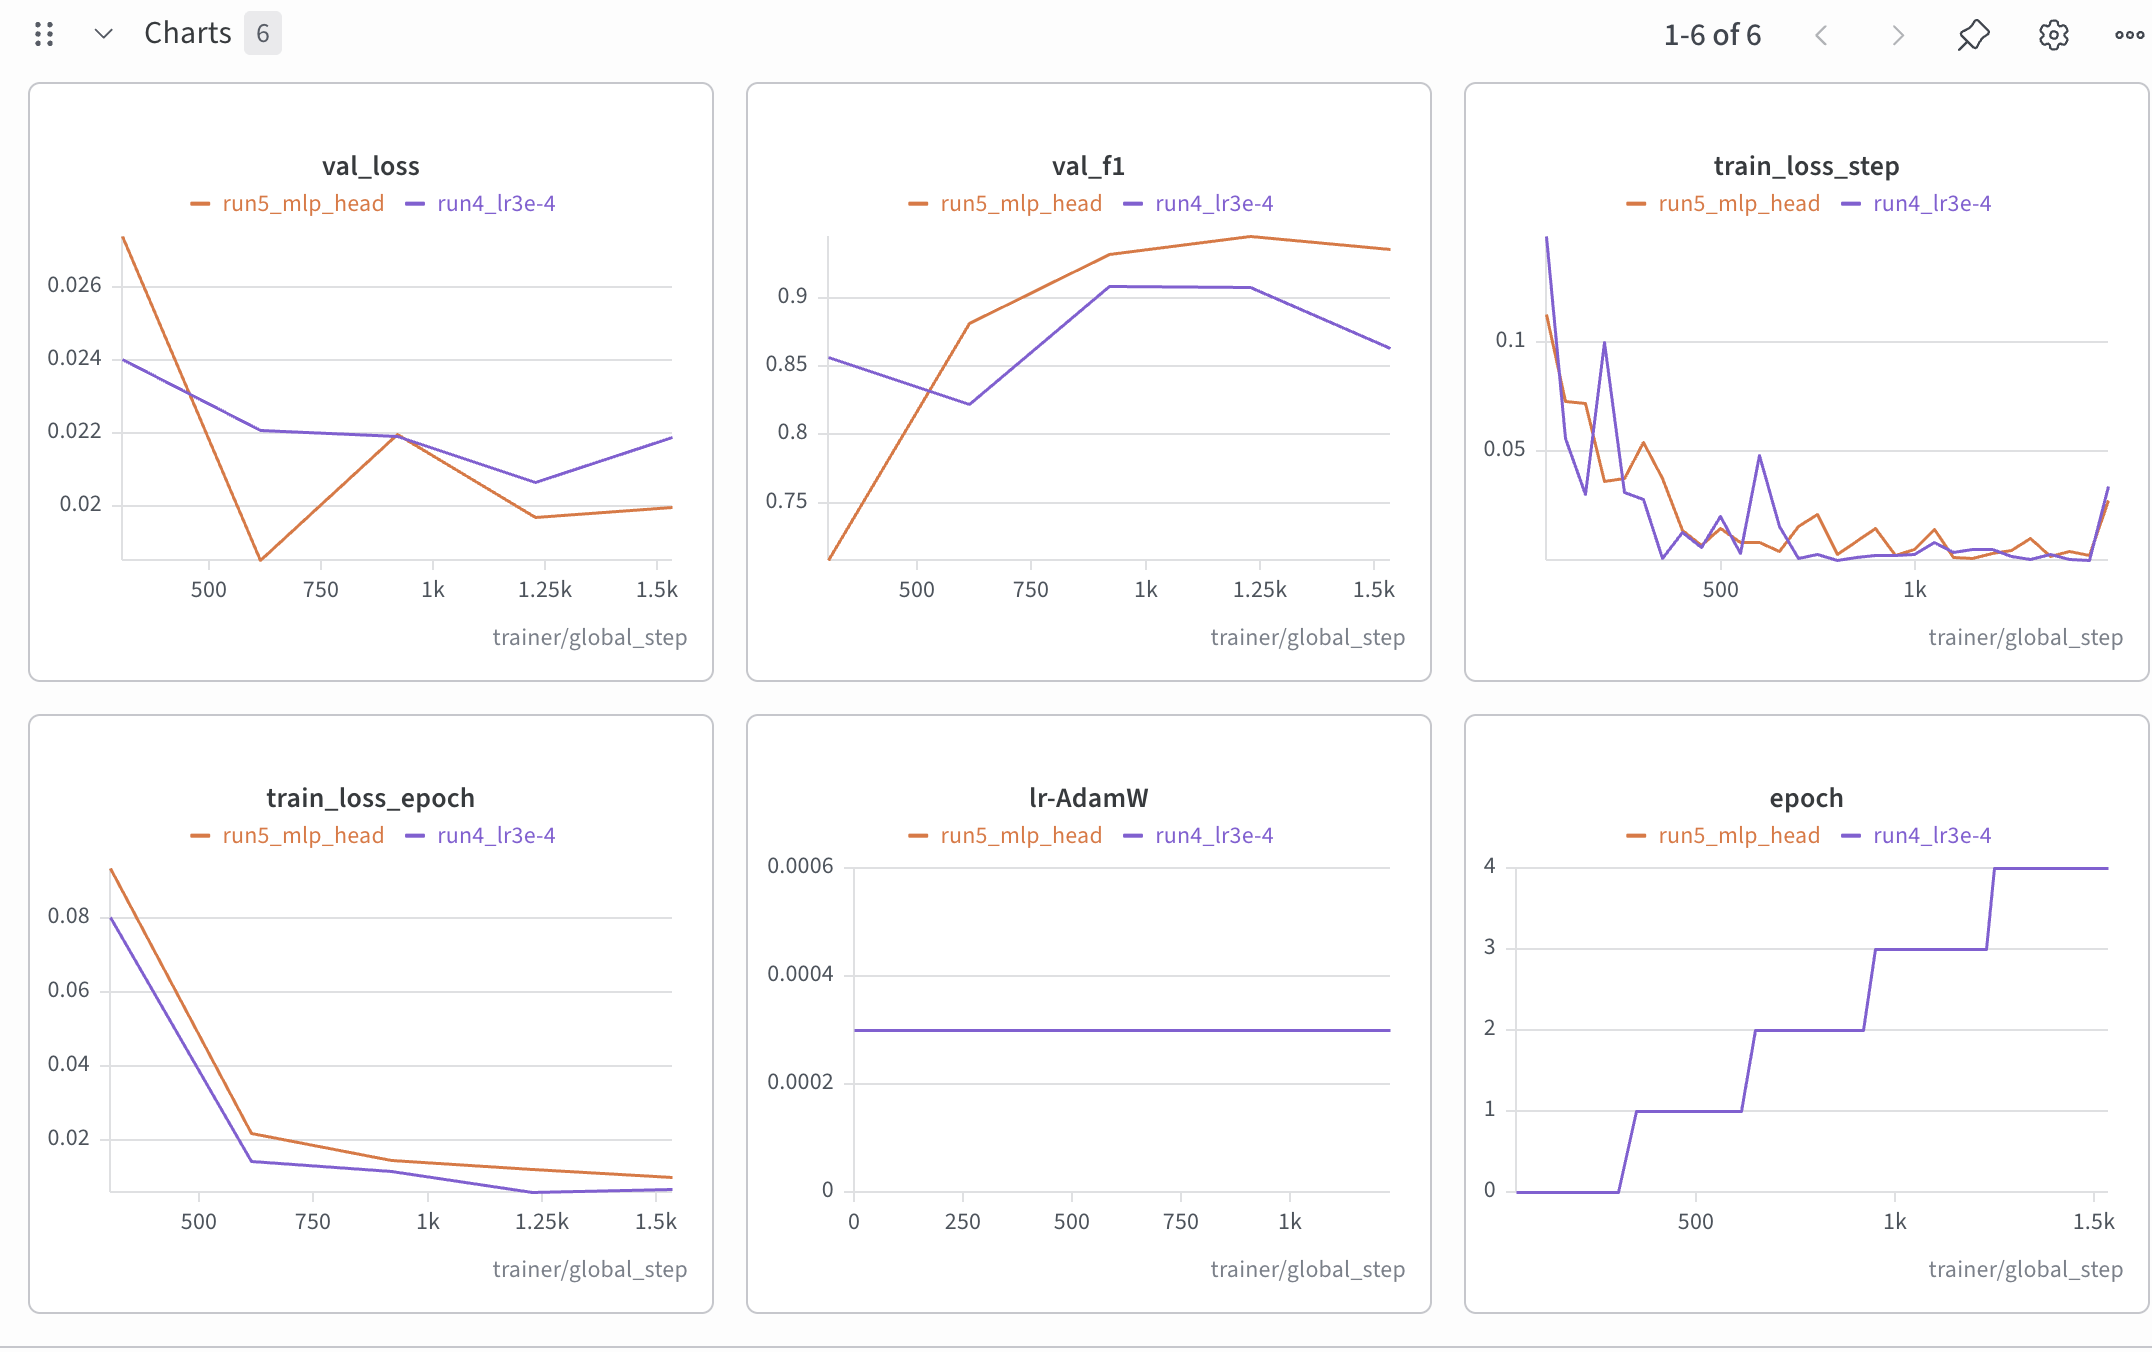

In [33]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [35]:
import glob

BEST_CKPT = sorted(glob.glob(os.path.join(CKPT_DIR, "run5_mlp_head*.ckpt")))[-1]
print(BEST_CKPT)

/content/drive/MyDrive/cats_dogs_pp/checkpoints/run5_mlp_head-epoch=03-val_f1=0.9450.ckpt


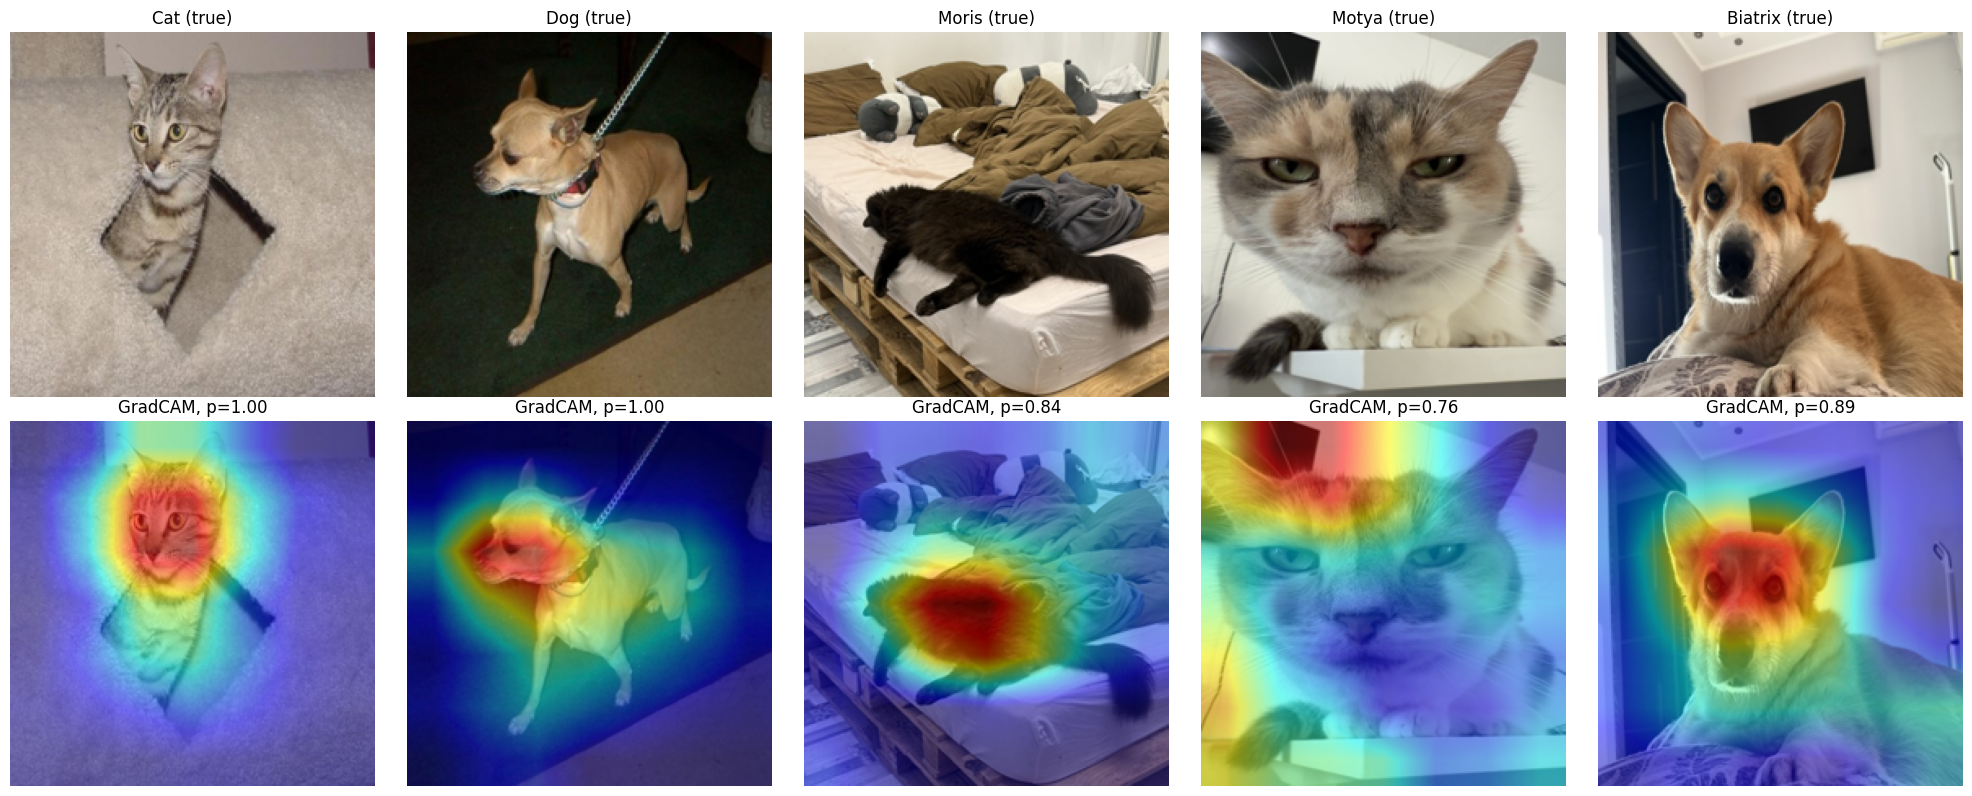

In [37]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np


model = PetsModel.load_from_checkpoint(BEST_CKPT).cuda().eval()
target_layers = [model.backbone.conv_head]
cam = GradCAM(model=model, target_layers=target_layers)

val_df = train_df[train_df["fold"] == 0]
fig, axes = plt.subplots(2, len(LABELS), figsize=(4 * len(LABELS), 8))

for col, label in enumerate(LABELS):
    row = val_df[val_df[label] == 1].iloc[0]
    img = Image.open(os.path.join(path, "train", f"{row['image_id']}.jpg")).convert("RGB")
    rgb = np.array(img.resize((IMG_SIZE, IMG_SIZE))) / 255.0
    x = val_tf(img).unsqueeze(0).cuda()

    heatmap = cam(input_tensor=x, targets=[ClassifierOutputTarget(col)])[0]
    prob = torch.sigmoid(model(x))[0, col].item()

    axes[0, col].imshow(rgb)
    axes[0, col].set_title(f"{label} (true)")
    axes[1, col].imshow(show_cam_on_image(rgb.astype(np.float32), heatmap, use_rgb=True))
    axes[1, col].set_title(f"GradCAM, p={prob:.2f}")
    for ax in axes[:, col]:
        ax.axis("off")

plt.tight_layout()
plt.show()

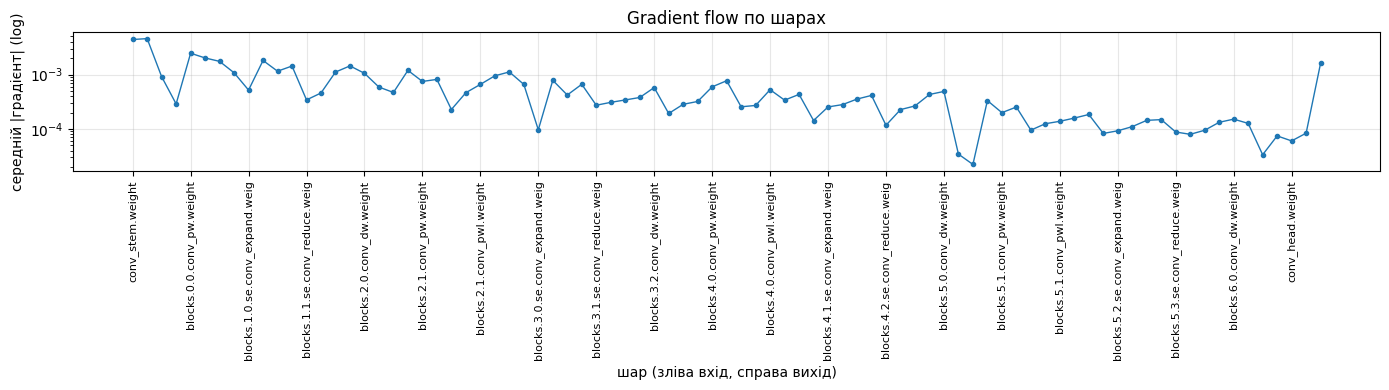

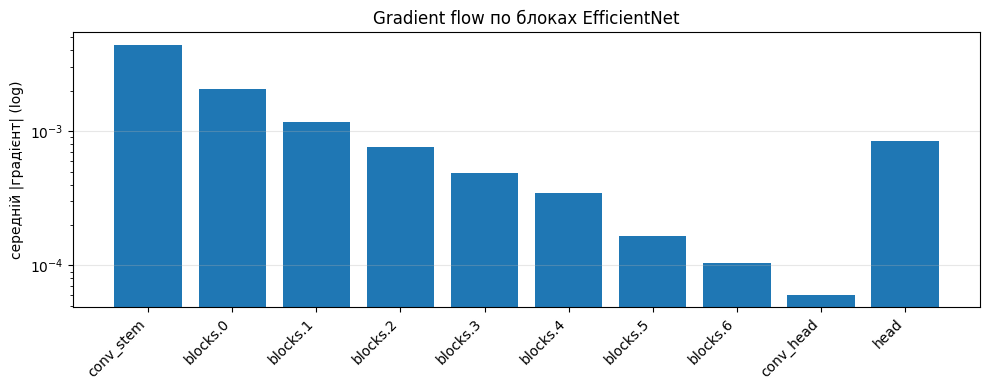

In [38]:
import torch
import numpy as np
import matplotlib.pyplot as plt

model = PetsModel.load_from_checkpoint(BEST_CKPT).cuda().train()
train_loader, _ = make_loaders(fold=0)

model.zero_grad()
for i, (x, y) in enumerate(train_loader):
    loss = model.criterion(model(x.cuda()), y.cuda())
    loss.backward()
    if i == 4:
        break


names, grads = [], []
for name, p in model.named_parameters():
    if p.grad is not None and p.dim() > 1:
        names.append(name)
        grads.append(p.grad.abs().mean().item())


plt.figure(figsize=(14, 4))
plt.semilogy(grads, marker=".", lw=1)
step = max(1, len(names) // 20)
plt.xticks(range(0, len(names), step),
           [names[i].replace("backbone.", "")[:30] for i in range(0, len(names), step)],
           rotation=90, fontsize=8)
plt.xlabel("шар (зліва вхід, справа вихід)")
plt.ylabel("середній |градієнт| (log)")
plt.title("Gradient flow по шарах")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


def block_of(name):
    parts = name.replace("backbone.", "").split(".")
    return ".".join(parts[:2]) if parts[0] == "blocks" else parts[0]

block_grads = {}
for n, g in zip(names, grads):
    block_grads.setdefault(block_of(n), []).append(g)

blocks = list(block_grads)
plt.figure(figsize=(10, 4))
plt.bar(blocks, [np.mean(block_grads[b]) for b in blocks])
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.ylabel("середній |градієнт| (log)")
plt.title("Gradient flow по блоках EfficientNet")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

Gradient flow

Gradients reach all layers, including the first one (conv_stem), so there is no vanishing
gradient. All values stay between 10⁻⁴ and 10⁻³, so there is no exploding gradient either.
Training is stable.

Model adequacy

We consider the model (EfficientNet-B0 + MLP head) adequate, based on four checks:

1. Validation score: val F1 macro = 0.945 on fold 0, a large improvement over the baseline (0.767).
2. Public LB: LB = [___]. [CV and LB are close / LB is lower than CV by ___], so our validation
   [reflects / does not fully reflect] the test performance.
3. Training: gradients reach all layers, and validation loss stays low and stable,
   so there is no strong overfitting.
4. GradCAM: the model focuses on [the animal / the background] when predicting the labels,
   including the rare pets (Moris, Motya, Biatrix).

Limitations: all experiments used only fold 0, and repeated runs of the same configuration
varied by ~0.05 because the validation fold has only ~8–11 images of each rare pet.

Model adequacy

The model (EfficientNet-B0 + MLP head) is adequate:
- it improved F1 from 0.767 to 0.945 on CV and from 0.767 to 0.918 on Public LB;
- CV and LB agree on the best model, so our validation works;
- gradients reach all layers and validation loss is stable, so training is healthy;
- GradCAM shows that the model focuses on [the animal / the background].

Limitation: experiments used only fold 0, so small differences between runs are noisy.